# 01 · Data check: the logged ants follow the rule exactly

**What this notebook shows.** Before training anything, we confirm the dataset is what we think it is: at every step an ant follows the rule with probability 1 - eps and moves uniformly at random with probability eps. This notebook also defines the two measuring sticks used everywhere later:
- **clear-choice rows**: steps where exactly one direction is best, so "did the ant follow the rule" has a yes/no answer;
- **loss floor**: the lowest loss any model can reach, which needs the true rule *and* the true eps.

**The rule.** Searching ant: if it sees food, go toward it; else follow the strongest food smell; with no signal, pick any direction. Carrying ant: same with home. With probability eps the ant ignores all of this and picks one of the 4 directions uniformly.

**Dataset.** `dataset_20261025_104552_105991`: 10 eps values (0.1 to 1.0), 100 runs (train 60 = 6 seeds per eps, val 20, test 20), 1500 steps × 100 ants per run, 19 numbers per state.

**Results (recorded run on the full dataset).**
- Every run passes the sanity checks (19 numbers per state, actions in 0 to 3, no NaN, previous action consistent on 99.8% or more of steps).
- On clear-choice rows the ant takes the rule's move with probability (1 - eps) + eps/4, matched to 3 decimals for all 10 eps (0.925 at eps 0.1, 0.625 at eps 0.5, 0.249 at eps 1.0).
- Normalization never changes the rule's answer (best direction and ties identical on 100% of rows).
- The share of clear-choice rows falls from 0.64 (eps 0.1) to 0.20 (eps 1.0).
- Loss floor on train: 1.152.

**Conclusion.** The logs are exactly "rule + uniform noise", so how often an ant departs from the rule is a valid measure of its eps, and the loss floor is a valid target for every model in notebooks 02 to 10. High-eps runs have far fewer clear-choice rows, so any eps estimate there rests on less evidence.

In [8]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Load the runs

In [9]:
runs = {split: load_split(split) for split in ["train", "val", "test"]}
for split, rs in runs.items():
    T, N, D = rs[0]["state"].shape
    print(f"{split:5s}: {len(rs):3d} runs | {T} steps x {N} ants x {D} numbers | "
          f"eps values: {sorted({r['eps'] for r in rs})}")

train:  60 runs | 1500 steps x 100 ants x 19 numbers | eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
val  :  20 runs | 1500 steps x 100 ants x 19 numbers | eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
test :  20 runs | 1500 steps x 100 ants x 19 numbers | eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 2. Sanity checks per run

In [10]:
def check_run(run):
    T, N, D = run["state"].shape
    a, prev = run["action"], run["prev_action"]
    has_prev = prev[1:].sum(-1) > 0                         # steps where prev_action is filled in
    prev_matches = (prev[1:].argmax(-1) == a[:-1])[has_prev].mean()
    return dict(run=run["name"], eps=run["eps"], T=T, N=N, D=D,
                action_min=int(a.min()), action_max=int(a.max()),
                any_nan=bool(np.isnan(run["state"]).any()),
                prev_action_matches=round(float(prev_matches), 4))


checks = pd.DataFrame([check_run(r) for split in runs for r in runs[split]])
print("all D == 19:            ", (checks.D == 19).all())
print("actions in 0..3:        ", ((checks.action_min >= 0) & (checks.action_max <= 3)).all())
print("no NaNs:                ", (~checks.any_nan).all())
print("prev_action consistent: ", (checks.prev_action_matches > 0.99).all(),
      f"(lowest run: {checks.prev_action_matches.min():.4f})")

all D == 19:             True
actions in 0..3:         True
no NaNs:                 True
prev_action consistent:  True (lowest run: 0.9977)


**Analysis.** All four checks pass in the recorded run. The previous-action field agrees with the logged action on 99.82% to 99.99% of steps rather than 100%. The cause of the small mismatch was not investigated; it is too small to matter for anything below.

## 3. Does the data follow the rule?

In [11]:
rows = []
for r in runs["train"]:
    s, a = r["state"].reshape(-1, 19), r["action"].reshape(-1)
    k = n_ties(s)
    clear = k == 1
    rows.append(dict(eps=r["eps"],
                     follows_rule=(a[clear] == best_dir(s)[clear]).mean(),   # measured
                     expected=1 - r["eps"] + r["eps"] / 4,                    # rule + uniform noise
                     share_clear=clear.mean(),                               # one best direction
                     share_no_signal=(k == 4).mean()))                       # nothing to follow
rule_table = pd.DataFrame(rows).groupby("eps").mean()
print(rule_table.round(3))
print(f"\nlargest |measured - expected|: {(rule_table.follows_rule - rule_table.expected).abs().max():.4f}")

     follows_rule  expected  share_clear  share_no_signal
eps                                                      
0.1         0.925     0.925        0.639            0.325
0.2         0.850     0.850        0.651            0.314
0.3         0.775     0.775        0.653            0.313
0.4         0.701     0.700        0.631            0.343
0.5         0.625     0.625        0.638            0.339
0.6         0.550     0.550        0.602            0.380
0.7         0.475     0.475        0.603            0.385
0.8         0.399     0.400        0.574            0.418
0.9         0.326     0.325        0.454            0.543
1.0         0.249     0.250        0.202            0.797

largest |measured - expected|: 0.0009


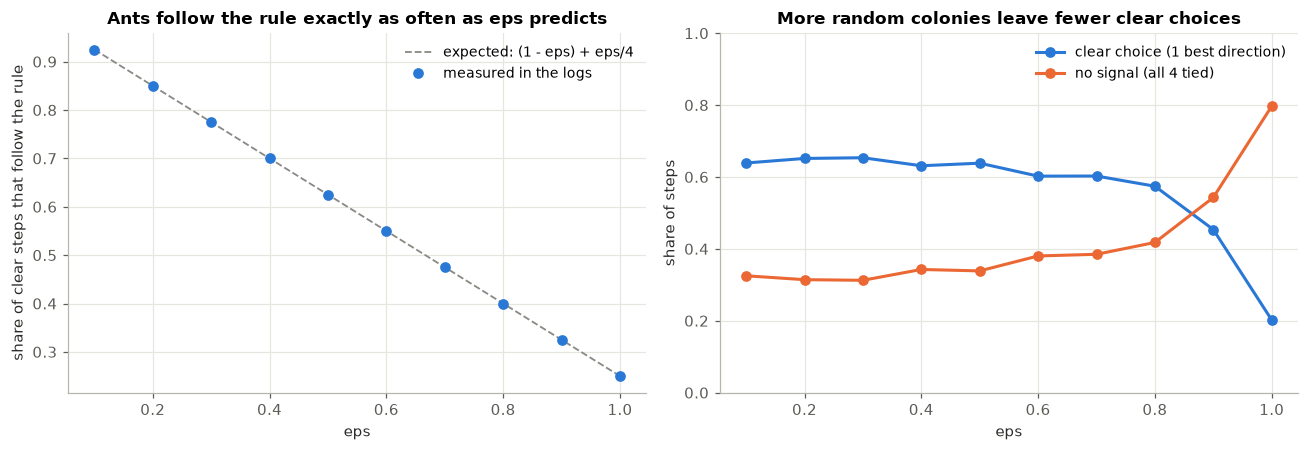

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(rule_table.index, rule_table.expected, color=C["gray"], ls="--", lw=1.2, label="expected: (1 - eps) + eps/4")
ax.plot(rule_table.index, rule_table.follows_rule, "o", color=C["blue"], label="measured in the logs")
ax.set(xlabel="eps", ylabel="share of clear steps that follow the rule",
       title="Ants follow the rule exactly as often as eps predicts")
ax.legend()

ax = axes[1]
ax.plot(rule_table.index, rule_table.share_clear, "-o", color=C["blue"], label="clear choice (1 best direction)")
ax.plot(rule_table.index, rule_table.share_no_signal, "-o", color=C["orange"], label="no signal (all 4 tied)")
ax.set(xlabel="eps", ylabel="share of steps", ylim=(0, 1),
       title="More random colonies leave fewer clear choices")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** In the recorded run the measured follow rate matches (1 - eps) + eps/4 to within 0.001 at every eps:

| eps | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|---|---|---|---|---|---|---|---|---|---|---|
| measured | 0.925 | 0.850 | 0.775 | 0.701 | 0.625 | 0.550 | 0.475 | 0.399 | 0.326 | 0.249 |
| share of clear rows | 0.639 | 0.651 | 0.653 | 0.631 | 0.638 | 0.602 | 0.603 | 0.574 | 0.454 | 0.202 |

So the noise model is confirmed from the data itself, not assumed. The right panel matters later: at eps 0.9 and 1.0 the colony builds few trails, most steps have no signal, and an eps estimate for those runs is based on fewer usable steps.

## 4. Normalization keeps the rule's answer

In [13]:
s_raw = np.concatenate([r["state"].reshape(-1, 19) for r in runs["val"]])
s_norm = normalize(s_raw)
print(f"rows checked:              {len(s_raw):,}")
print(f"best direction unchanged:  {(best_dir(s_raw) == best_dir(s_norm)).mean():.6f}   (want 1)")
print(f"number of ties unchanged:  {(n_ties(s_raw) == n_ties(s_norm)).mean():.6f}   (want 1)")
print(f"normalized range:          {s_norm.min():.3f} to {s_norm.max():.3f}")

rows checked:              3,000,000
best direction unchanged:  1.000000   (want 1)
number of ties unchanged:  1.000000   (want 1)
normalized range:          0.000 to 1.000


**Analysis.** Both are exactly 1.0 in the recorded run, so every model can be trained on normalized inputs without changing what the rule would do. (Raw smell values are tiny: most top-two smell gaps are below 0.03. That matters for notebook 02.)

## 5. The loss floor

In [14]:
s_train = np.concatenate([r["state"].reshape(-1, 19) for r in runs["train"]])
eps_train = np.concatenate([np.full(r["action"].size, r["eps"]) for r in runs["train"]])
floor_rows = true_entropy(s_train, eps_train)

floor_table = pd.Series(floor_rows).groupby(eps_train).mean()
print("loss floor per eps (lowest possible cross-entropy, needs the true eps):")
print(floor_table.round(4).to_string())
print(f"\noverall train floor: {floor_rows.mean():.4f}")
del s_train, eps_train, floor_rows, s_raw, s_norm

loss floor per eps (lowest possible cross-entropy, needs the true eps):
0.1    0.7065
0.2    0.8538
0.3    0.9816
0.4    1.1001
0.5    1.1838
0.6    1.2622
0.7    1.3149
0.8    1.3551
0.9    1.3799
1.0    1.3863

overall train floor: 1.1524


**Analysis.** The recorded train floor is 1.152. It rises with eps because noisier ants are less predictable. From here on every model is scored as **loss above floor**: 0 means it predicts as well as someone who knows both the rule and the ant's true eps.